# Transfer to shifted images with a frozen encoder

How much can a learned source encoder be reused for a shifted target domain?

I train a CNN on source training images, then adapt only its classifier or the full network using translated copies of the same training identities. The held-out image identities never enter source pretraining. A separate optional cell shows the official ImageNet ResNet18 route.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import json
import os
from pathlib import Path
import sys

import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    DataSplit,
    Trainer,
    TrainConfig,
    classification_scores,
    digits_data,
    image_grid,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "07_transfer_and_frozen_features"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Data and split

The 1,797 handwritten digit images come from `sklearn.datasets.load_digits`. Intensities are divided by the known sensor maximum of 16. The original 8 by 8 images are resized to 16 by 16 for the convolutional experiments. Resizing adds no measured detail. The split is stratified: 60% train, 20% validation and 20% test.

{'train': 1077, 'validation': 360, 'test': 360}


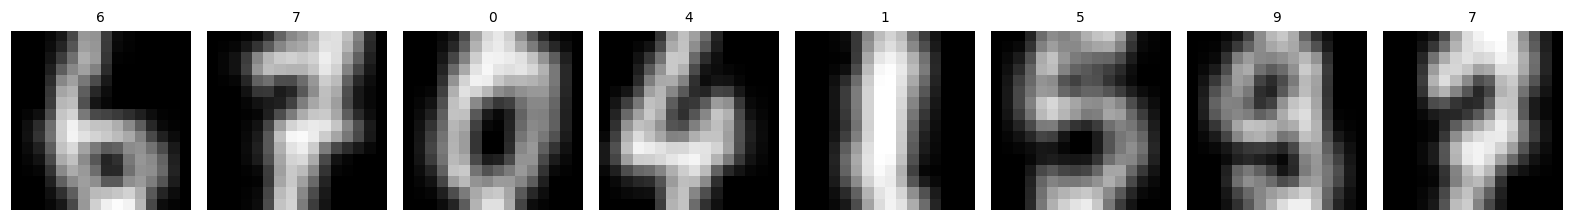

In [5]:
from vision_projects.models import LeNet

data = digits_data()
train_loader, validation_loader, test_loader = data.loaders()
train_images, train_labels = data.train.tensors
print(
    {
        "train": len(data.train),
        "validation": len(data.validation),
        "test": len(data.test),
    }
)
image_grid(train_images[:8], output / "examples.png", train_labels[:8].tolist())

## Source encoder

Source training uses clean digits. Validation selects its checkpoint. This controlled source model is a learned pretrained encoder for the next stage; it carries no ImageNet pretraining.

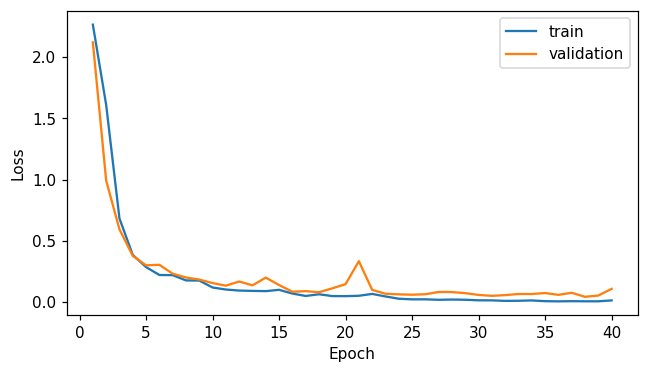

{'accuracy': 0.9777777777777777, 'macro_f1': 0.9779842820558464, 'nll': 0.04461308520021039}


In [7]:
source_model = LeNet()
history = Trainer(source_model, nn.CrossEntropyLoss(), TrainConfig(epochs=EPOCHS)).fit(
    train_loader, validation_loader
)
plot_history(history, output / "source_loss.png")
source_weights = {
    name: value.detach().clone() for name, value in source_model.state_dict().items()
}
source_validation, source_targets = predict(source_model, validation_loader)
print(classification_scores(source_validation, source_targets))

## Target domain

The target domain shifts images by two pixels rightward and zero-fills the left border. Source and target training views share identity, so this experiment measures adaptation to a transformation. It does not measure transfer to unseen semantic classes.

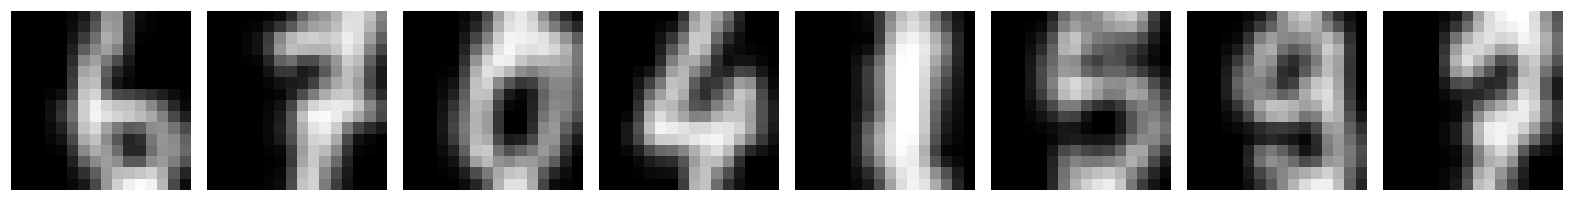

In [9]:
def target_view(dataset):
    images, labels = dataset.tensors
    translated = torch.roll(images, 2, -1).clone()
    translated[..., :2] = 0
    return TensorDataset(translated, labels)


target_data = DataSplit(
    target_view(data.train), target_view(data.validation), target_view(data.test)
)
target_train, target_validation, target_test = target_data.loaders()
image_grid(target_data.train.tensors[0][:8], output / "target.png")

## Freeze or fine-tune

Freezing the encoder removes it from gradient updates. Evaluation mode is set by the shared loop at prediction time. I reset the classifier so the two adaptation runs begin from the same target head initialization.

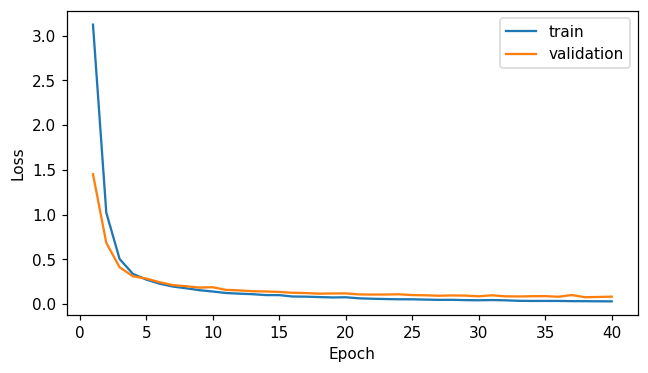

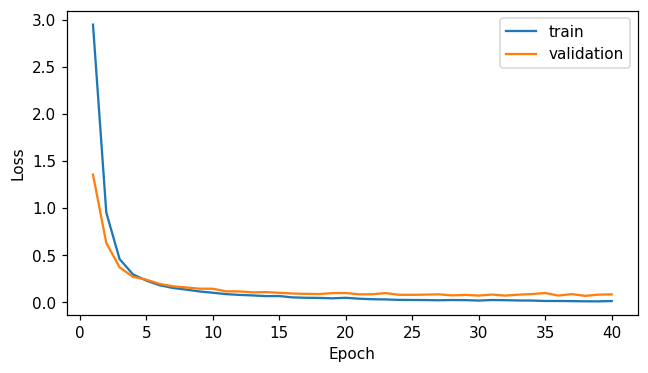

         mode  trainable_parameters  accuracy  macro_f1       nll
0      frozen                 25290  0.977778  0.977691  0.077222
1  fine_tuned                 28026  0.980556  0.980465  0.069802


In [11]:
adaptation, models = [], {}
for mode in ["frozen", "fine_tuned"]:
    seed_everything()
    candidate = LeNet()
    candidate.load_state_dict(source_weights)
    candidate.classifier[-1].reset_parameters()
    if mode == "frozen":
        for parameter in candidate.features.parameters():
            parameter.requires_grad_(False)
    target_train, target_validation, target_test = target_data.loaders()
    history = Trainer(
        candidate,
        nn.CrossEntropyLoss(),
        TrainConfig(epochs=EPOCHS, learning_rate=0.001),
    ).fit(target_train, target_validation)
    plot_history(history, output / f"{mode}_loss.png")
    logits, labels = predict(candidate, target_validation)
    adaptation.append(
        {
            "mode": mode,
            "trainable_parameters": sum(
                p.numel() for p in candidate.parameters() if p.requires_grad
            ),
            **classification_scores(logits, labels),
        }
    )
    models[mode] = candidate
print(pd.DataFrame(adaptation))

## Target test and an ImageNet option

The target test is evaluated after adaptation choices are complete. The ImageNet path is opt-in because it downloads weights and expects RGB preprocessing. Constructing a model with `weights=None` would be a random initialization and would not measure pretrained transfer.

In [13]:
comparison = []
logits, labels = predict(source_model, target_test)
comparison.append(
    {"mode": "source_without_adaptation", **classification_scores(logits, labels)}
)
for mode, candidate in models.items():
    logits, labels = predict(candidate, target_test)
    comparison.append({"mode": mode, **classification_scores(logits, labels)})
print(pd.DataFrame(comparison))
RUN_IMAGENET = os.environ.get("PROJECT_IMAGENET", "0") == "1"
if RUN_IMAGENET:
    from torchvision.models import resnet18, ResNet18_Weights

    weights = ResNet18_Weights.DEFAULT
    from vision_projects.models import FrozenResNetClassifier

    imagenet_model = FrozenResNetClassifier(resnet18(weights=weights))
    preprocessing = weights.transforms()

    def imagenet_dataset(dataset):
        images, labels = dataset.tensors
        rgb = images.repeat(1, 3, 1, 1)
        return TensorDataset(preprocessing(rgb), labels)

    imagenet_data = DataSplit(
        *(
            imagenet_dataset(dataset)
            for dataset in [target_data.train, target_data.validation, target_data.test]
        )
    )
    source_train, source_val, source_test = imagenet_data.loaders(16)
    Trainer(
        imagenet_model,
        nn.CrossEntropyLoss(),
        TrainConfig(epochs=EPOCHS, learning_rate=0.001),
    ).fit(source_train, source_val)
    logits, labels = predict(imagenet_model, source_test)
    comparison.append(
        {"mode": "imagenet_frozen", **classification_scores(logits, labels)}
    )
results = {
    "validation": adaptation,
    "target_test": comparison,
    "imagenet_run": RUN_IMAGENET,
}

                        mode  accuracy  macro_f1       nll
0  source_without_adaptation  0.625000  0.611989  2.685867
1                     frozen  0.963889  0.963715  0.112040
2                 fine_tuned  0.961111  0.960768  0.109797


## Reading the result

Frozen features reduce trainable parameters, but source features can retain sensitivity to placement. Full fine-tuning can correct that sensitivity and can also overfit a small target set. The optional ImageNet result is present only if that route actually ran.

In [15]:
result_path = root / "results" / "07_transfer_and_frozen_features.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/07_transfer_and_frozen_features.json


## Next experiment

Replace target translations with a separate handwritten-digit dataset, such as USPS. Keep class mapping explicit, document the image conversion and avoid selecting adaptation settings using its final test labels.

## Sources

UniPd Computer Vision and Cognitive Systems: uploaded filtering, SIFT, BoW, MLP and CNN notebooks. [PyTorch transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.